# Multicellular programmes with DIALOGUE

*Python port of the R vignette [Multicellular programmes with DIALOGUE](https://gregorlueg.github.io/bixverse/articles/dialogue.html). Original author: Gregor Lueg.*

## Intro

Most programme discovery methods ask what varies together *within* a cell type.
NMF on the T cells gives you T cell programmes; Hotspot on the macrophages
gives you macrophage programmes. Neither tells you whether the T cell
programme and the macrophage programme are the same thing seen from two sides.

[DIALOGUE](https://doi.org/10.1038/s41587-022-01288-0) asks the other question.
It looks for multicellular programmes (MCPs): axes of variation that show up in
several cell types *at once*, sample by sample. If macrophages in a biopsy sit
high on some axis and the epithelial cells in the same biopsy also sit high,
and that holds across enough biopsies, then whatever those cells are doing is
coordinated rather than independent.

Three stages, and it is worth knowing the shape before you run it:

1. Each cell type's features are averaged to one row per sample and put through
   a sparse multi-CCA. That gives every programme a weight vector per cell type
   and a provisional gene signature.
2. For every ordered pair of cell types and every candidate gene, a mixed model
   asks whether a cell's own programme score tracks the partner cell type's
   expression of that gene in the same sample. The random intercept is over
   samples.
3. The partners are meta-analysed, and the scores are refit onto the surviving
   genes by non-negative least squares.

If you have not read the [design choices](design_single_cell.ipynb) and the
[introductory vignette](thinking_single_cell.ipynb), please do so first; this
one assumes you know how `SingleCells`, subsets and on-disk storage work.

> **DIALOGUE needs a study design, not just a lot of cells**
>
> Because stage one works on per-sample averages, DIALOGUE needs **multiple
> samples and multiple cell types, with every cell type captured in every
> sample**. `bixverse` hard-errors below five samples present in all cell
> types, and drops samples that do not clear `abn_c` cells for a given cell
> type.
>
> This is the thing that catches people out. A beautiful 500k cell atlas from
> one donor is useless here. Ten scrappy biopsies are not.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy.stats import mannwhitneyu

import bixverse as bv
from bixverse.params import DialoguePmdParams

## The data

We use the ulcerative colitis subset from the DIALOGUE paper, originally from
[Smillie, et al.](https://doi.org/10.1016/j.cell.2019.06.029). 5,374 cells
across five cell subtypes and 30 donors: twelve healthy, eighteen with UC who
each contributed an inflamed and a non-inflamed biopsy.

One provenance note. The published matrix holds `log2(TPM / 10 + 1)` and the
raw counts were never released, so the file served here has been linearised
back to the TPM/10 scale and rounded to integers. It therefore loads like any
count matrix and picks up `bixverse`'s own log CPM on the way in. That is fine
for DIALOGUE, which only ever reads the normalised layer.

In [2]:
dialogue_h5ad = bv.io.download_dialogue_uc()

tempdir_dlg = tempfile.TemporaryDirectory()

sc = bv.io.load_h5ad(Path(tempdir_dlg.name) / "dialogue_uc", dialogue_h5ad)

sc

SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpgs7rltau/dialogue_uc',
  cells=5374 (kept 5374), genes=6329,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

Before anything else, look at the design. This is the table that decides
whether DIALOGUE can run at all.

In [3]:
obs = sc.obs(filtered=True)

obs.pivot(
    on="clinical_status",
    index="cell_subtype",
    values="cell_id",
    aggregate_function="len",
    sort_columns=True,
).fill_null(0).sort("cell_subtype")

cell_subtype,Healthy,Inflamed,Non-inflamed
str,u32,u32,u32
"""CD8+ IELs""",409,145,198
"""CD8+ IL17+""",24,45,30
"""CD8+ LP""",429,367,370
"""Macrophages""",543,450,459
"""TA2""",723,568,614


`CD8+ IL17+` is the problem: few cells in total, and completely absent from a
good chunk of the thirty donors.

In [4]:
il17 = obs.filter(pl.col("cell_subtype") == "CD8+ IL17+")

print(
    f"CD8+ IL17+: {il17.height} cells, absent from "
    f"{obs['sample'].n_unique() - il17['sample'].n_unique()} of "
    f"{obs['sample'].n_unique()} donors"
)

CD8+ IL17+: 99 cells, absent from 11 of 30 donors


A cell type missing from a sample means that sample cannot contribute to any
pair involving it, so the sensible move is to drop the cell type rather than
lose the samples. pertpy's DIALOGUE tutorial does the same thing on the same
data.

In [5]:
sc.set_cells_to_keep(
    obs.filter(pl.col("cell_subtype") != "CD8+ IL17+")["cell_id"].to_list()
)

bv.pp.find_hvg(sc, hvg_no=2000)

obs = sc.obs(filtered=True)
cell_types = sorted(obs["cell_subtype"].unique().to_list())

print(cell_types)
print(
    "fewest cells per donor and cell type:",
    obs.group_by("sample", "cell_subtype").len()["len"].min(),
    "| donor x cell type combinations:",
    obs.select("sample", "cell_subtype").n_unique(),
)

['CD8+ IELs', 'CD8+ LP', 'Macrophages', 'TA2']
fewest cells per donor and cell type: 2 | donor x cell type combinations: 120


Four cell types, thirty donors, all 120 donor-by-cell-type combinations
present, and the sparsest one still has cells in it. That is a design
DIALOGUE can work with.

## Per-cell-type features

This is the step to get right, and the one the documentation warns about: the
`features` you hand DIALOGUE must be computed **per cell type**, not sliced out
of a global PCA. A global PCA's leading components mostly separate the cell
types from each other, so slicing it hands every cell type the same axis and
DIALOGUE dutifully reports that the cell types agree with themselves.

So: subset, find variable genes within the subset, run a PCA within the subset.

In [6]:
features = {}

for ct in cell_types:
    sub = bv.SingleCellsSubset(sc, "cell_subtype", ct)
    bv.pp.find_hvg(sub, hvg_no=2000)
    bv.pp.calculate_pca(sub, no_pcs=10)

    # PCA rows follow the subset's kept cells
    pcs = sub.cache.pca_factors
    features[ct] = pl.DataFrame(
        {
            "cell_id": sub.cell_ids(filtered=True),
            **{f"PC_{i + 1}": pcs[:, i] for i in range(pcs.shape[1])},
        }
    )

{ct: f.shape for ct, f in features.items()}

{'CD8+ IELs': (752, 11),
 'CD8+ LP': (1166, 11),
 'Macrophages': (1452, 11),
 'TA2': (1905, 11)}

`features` is a dict of polars frames keyed by the cell type labels, each a
`cell_id` column plus the PCs. Rows are matched by id rather than position,
so the order does not matter, but the coverage does: every cell of that type
has to be in there.

## Running it

Three parameter classes, one per stage (`DialoguePmdParams`,
`DialogueHlmParams`, `DialogueRefineParams`). The defaults follow upstream's
`DLG.get.param`, and the two knobs worth thinking about live in
`DialoguePmdParams`: `k` is how many programmes you are asking for, with no
sweep to help you pick it, and `n_permutations` sets the resolution of the
empirical p-value.

We ask for three programmes, matching what pertpy reports on this data.

In [7]:
dlg_res = bv.dialogue.dialogue(
    sc,
    "cell_subtype",
    "sample",
    features,
    quality_col="cell_q",
    pmd_params=DialoguePmdParams(k=3, n_permutations=100),
)

dlg_res

DialogueResult (multicellular programmes)
  Source class:     SingleCells
  Cell types:       4 (CD8+ IELs, CD8+ LP, Macrophages, TA2)
  Shared samples:   30
  Programmes:       3
    mcp_00 - worst pair p: 0.0448 | spans 4 cell type(s)
    mcp_01 - worst pair p: 0.5414 | spans 3 cell type(s)
    mcp_02 - worst pair p: 0.09402 | spans 4 cell type(s)
  Genes with a verdict: 1278
  Signature genes:  1115 permissive | 719 strict

`quality_col="cell_q"` is the per-cell quality score the original paper
shipped with this data. Leave it `None` and `bixverse` falls back to the
z-scored log library size instead. That choice matters more than it looks, and
we come back to it below.

## Reading the output

`get_results()` gives the programme table: one row per programme per pair of
cell types, with the empirical p-value and the correlation between the two
cell types' sample-level scores. Programmes are 0-based, `mcp_00` is
programme 0.

In [8]:
bv.dialogue.get_results(dlg_res)

programme,cell_type_a,cell_type_b,emp_p,pair_cor
i32,str,str,f64,f64
0,"""CD8+ IELs""","""CD8+ LP""",0.044802,0.918508
1,"""CD8+ IELs""","""CD8+ LP""",0.048171,0.752837
2,"""CD8+ IELs""","""CD8+ LP""",0.082918,0.624747
0,"""CD8+ IELs""","""Macrophages""",0.044802,0.878346
1,"""CD8+ IELs""","""Macrophages""",0.044802,0.808002
…,…,…,…,…
1,"""CD8+ LP""","""TA2""",0.2442,0.514714
2,"""CD8+ LP""","""TA2""",0.055517,0.652043
0,"""Macrophages""","""TA2""",0.044802,0.912773


A programme is only interesting if it holds up across *every* pair, so the
number to look at is the worst p in each programme, which is what the repr
reports. The empirical p is a one-sided rank sum test of the observed fit
against the `n_permutations - 1` permuted ones, so it has a floor: about 0.045
at `n_permutations=100`, which `mcp_00` hits in every pair. Do not read too
much into the exact values; raise it for anything you intend to believe.

`refit_fidelity` says how well each cell type's score survived stage three,
i.e. how much of the programme is really carried by the genes that passed the
mixed model.

In [9]:
dlg_res.refit_fidelity.with_columns(pl.selectors.starts_with("mcp_").round(3))

cell_type,mcp_00,mcp_01,mcp_02
str,f64,f64,f64
"""CD8+ IELs""",0.944,0.547,0.796
"""CD8+ LP""",0.949,0.703,0.758
"""Macrophages""",0.985,0.877,0.877
"""TA2""",0.938,1.0,0.875


The signatures come in two flavours. `permissive` and `strict` are nested by
evidence rather than by threshold, and `strict` is the one to quote.

In [10]:
(
    dlg_res.signatures.filter(pl.col("list") == "strict")
    .group_by("cell_type", "programme", "direction")
    .len()
    .pivot(on="direction", index=["cell_type", "programme"], values="len")
    .sort("cell_type", "programme")
)

cell_type,programme,down,up
str,i32,u32,u32
"""CD8+ IELs""",0,25,70
"""CD8+ IELs""",1,null,3
"""CD8+ IELs""",2,6,1
"""CD8+ LP""",0,57,73
"""CD8+ LP""",1,6,5
…,…,…,…
"""Macrophages""",0,154,180
"""Macrophages""",1,1,20
"""Macrophages""",2,29,6


## Does it track the disease?

The scores are a dict, one frame of `cell_id` plus `mcp_00`, ... per cell
type. Average them up to the donor and compare across UC status.

In [11]:
obs_cols = obs.select(
    "cell_id", "sample", "pathology", "clinical_status", "lib_size", "cell_q"
)


def collect_scores(res: bv.dialogue.DialogueResult) -> pl.DataFrame:
    """All cell types' scores in one long frame with the obs columns."""
    return pl.concat(
        [s.with_columns(pl.lit(ct).alias("cell_type")) for ct, s in res.scores.items()]
    ).join(obs_cols, on="cell_id")


def per_sample_test(scores: pl.DataFrame, mcp: str) -> pl.DataFrame:
    """Donor means of one programme, Wilcoxon rank sum test per cell type."""
    per_sample = scores.group_by("sample", "cell_type", "pathology").agg(
        pl.col(mcp).mean()
    )
    rows = []
    for ct in cell_types:
        d = per_sample.filter(pl.col("cell_type") == ct)
        groups = d.partition_by("pathology", as_dict=True)
        x, y = (g[mcp].to_numpy() for g in groups.values())
        rows.append({"cell_type": ct, "p": mannwhitneyu(x, y).pvalue})
    return pl.DataFrame(rows).with_columns(pl.col("p").round_sig_figs(3))


score_df = collect_scores(dlg_res)

per_sample = score_df.group_by("sample", "cell_type", "pathology").agg(
    pl.selectors.starts_with("mcp_").mean()
)

per_sample_test(score_df, "mcp_00")

cell_type,p
str,f64
"""CD8+ IELs""",0.000655
"""CD8+ LP""",0.0012
"""Macrophages""",0.0149
"""TA2""",0.00056


`mcp_00` separates UC donors from healthy ones in all four cell types at once,
which is the thing DIALOGUE exists to find. Plotted:

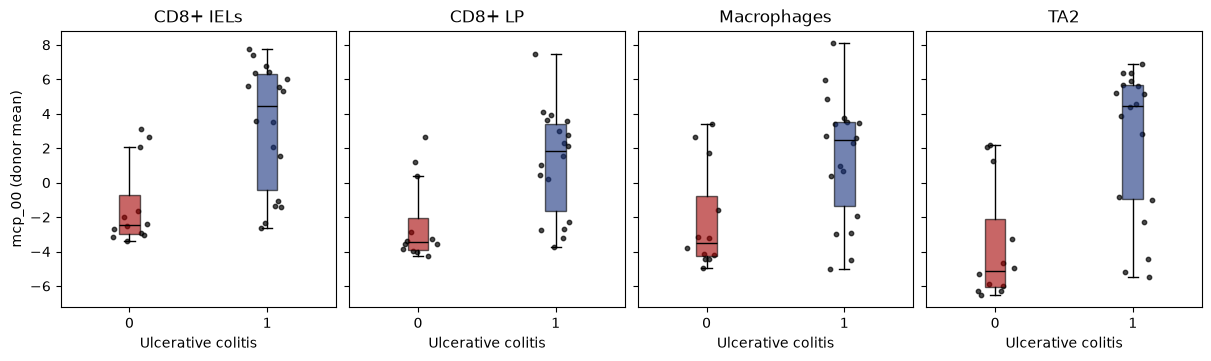

In [12]:
cols = bv.pl.bx_colors("main", n=2)
pathologies = sorted(per_sample["pathology"].unique().to_list())
rng = np.random.default_rng(42)

fig, axes = plt.subplots(
    1, len(cell_types), figsize=(12, 3.5), sharey=True, layout="constrained"
)
for ax, ct in zip(axes, cell_types, strict=True):
    d = per_sample.filter(pl.col("cell_type") == ct)
    vals = [
        d.filter(pl.col("pathology") == p)["mcp_00"].to_numpy() for p in pathologies
    ]
    bp = ax.boxplot(
        vals,
        tick_labels=pathologies,
        showfliers=False,
        patch_artist=True,
        medianprops={"color": "black"},
    )
    for patch, c in zip(bp["boxes"], cols, strict=True):
        patch.set_facecolor(c)
        patch.set_alpha(0.6)
    for i, v in enumerate(vals):
        ax.scatter(
            i + 1 + rng.uniform(-0.15, 0.15, v.size), v, s=10, color="black", alpha=0.7
        )
    ax.set_title(ct)
    ax.set_xlabel("Ulcerative colitis")
axes[0].set_ylabel("mcp_00 (donor mean)")
plt.show()

## Before you believe it: check the confounders

Here is where a vignette that wanted to look good would stop. Do not stop here.

A programme that shows up in every cell type at once is exactly what a
*technical* axis looks like. Depth, capture efficiency and ambient RNA hit all
cell types in a sample together, which is precisely the signature DIALOGUE is
built to detect. So before reading any biology into `mcp_00`, correlate it
against the quality covariates.

In [13]:
def quality_cor(scores: pl.DataFrame, mcp: str) -> pl.DataFrame:
    """Spearman correlation of one programme with the quality covariates per
    cell type."""
    return (
        scores.group_by("cell_type")
        .agg(
            pl.corr(mcp, cov, method="spearman").round(3).alias(f"rho_{cov}")
            for cov in ("lib_size", "cell_q")
        )
        .sort("cell_type")
    )


quality_cor(score_df, "mcp_00")

cell_type,rho_lib_size,rho_cell_q
str,f64,f64
"""CD8+ IELs""",-0.445,-0.146
"""CD8+ LP""",-0.555,-0.033
"""Macrophages""",-0.586,-0.002
"""TA2""",-0.591,0.072


That is not a small correlation. `mcp_00` is tracking library size at
`|rho| ~ 0.5` in every cell type (the sign of a programme is arbitrary), while
`cell_q` barely moves with it. And library size itself differs between the UC
and healthy donors on this subset. One oddity of this file: library size is
the total of the rounded TPM/10 values, so it only varies by a few percent and
is not sequencing depth in the usual sense. It is still a technical axis.

In [14]:
donor_lib = obs.group_by("sample", "pathology").agg(pl.col("lib_size").mean())
lib_groups = donor_lib.partition_by("pathology", as_dict=True)

{
    "mean_lib_size": {k[0]: round(g["lib_size"].mean()) for k, g in lib_groups.items()},
    "p": float(
        mannwhitneyu(*(g["lib_size"].to_numpy() for g in lib_groups.values())).pvalue
    ),
}

{'mean_lib_size': {1: 90961, 0: 92492}, 'p': 0.01177435333282468}

So a good chunk of what we just called a disease programme is a technical axis
wearing a lab coat.

The fix is to condition on the right covariate. `cell_q` is the paper's own
quality score and it barely correlates with `mcp_00`, so it was never going
to absorb this. The library-size covariate will.

In [15]:
dlg_lib = bv.dialogue.dialogue(
    sc,
    "cell_subtype",
    "sample",
    features,
    quality_col=None,
    pmd_params=DialoguePmdParams(k=3, n_permutations=100),
)

score_lib = collect_scores(dlg_lib)

quality_cor(score_lib, "mcp_00")

cell_type,rho_lib_size,rho_cell_q
str,f64,f64
"""CD8+ IELs""",-0.056,-0.109
"""CD8+ LP""",-0.242,0.27
"""Macrophages""",-0.274,-0.013
"""TA2""",-0.185,0.475


Much better. Two things to notice about what changed and what did not.

The programme table and the p-values are **identical** to the first run. That
is not a bug: the quality covariate only enters stage two, so stage one's
decomposition and its permutation null never saw it.

In [16]:
assert dlg_res.programmes.equals(dlg_lib.programmes)

What did change is the signature. Conditioning on library size drops the strict gene
count by more than half, because the genes that were only there to track
library size no longer clear the mixed model.

In [17]:
n_strict = {
    name: res.signatures.filter(pl.col("list") == "strict").height
    for name, res in (("cell_q", dlg_res), ("lib_size", dlg_lib))
}

n_strict

{'cell_q': 719, 'lib_size': 328}

And the disease association survives.

In [18]:
per_sample_test(score_lib, "mcp_00")

cell_type,p
str,f64
"""CD8+ IELs""",0.000212
"""CD8+ LP""",0.00556
"""Macrophages""",0.00923
"""TA2""",0.0118


So there is a real coordinated programme here, it is just a good deal smaller
than the first run advertised. That is the normal outcome of doing this check,
and it is why you do it.

## Caveats and what is next

A few things worth knowing before you point this at your own data.

- **`k` has no sweep.** Unlike `bv.nmf.nmf_k_sweep()`, there is no diagnostic to
  pick the number of programmes. Run a few values and look at whether the extra
  programmes hold up across every pair.
- **`satterthwaite` dominates the runtime.** Turning it off in
  `DialogueHlmParams` falls back to the residual count for the degrees of
  freedom, which is faster and usually close enough for a first pass.
- **The random intercept level is a real modelling choice.** We used the donor,
  matching the original analysis. Using the biopsy instead (sample and
  `clinical_status` pasted together) would let the inflamed and non-inflamed
  samples from one patient separate, at the cost of samples that then fall
  below `abn_c`.
- **Meta cells have to be built within samples.** Otherwise the random
  intercept has no well-defined level. `bv.metacells.meta_cells_per_group()`
  with `group_col` set to your sample column does exactly that, and
  `bv.dialogue.dialogue()` takes `MetaCells` the same way it takes
  `SingleCells` (features keyed by `meta_cell_id`). You have to aggregate the
  features over each meta cell's membership yourself.
- **This is a four-cell-type slice of a fifty-one-cell-type atlas.** The
  published UC programme spanned cell types that are simply not in this file,
  so partial agreement with the paper is the expected result rather than a
  failure.

## Clean up

In [19]:
tempdir_dlg.cleanup()